# Volatilité du change euro-dollar : le passé permet-il de prévoir l'amplitude des variations à venir ?

**Question.** Les variations passées du taux de change EUR/USD permettent-elles de prévoir l'amplitude des variations à venir ?

**Tâche.** Régression sur la valeur absolue du rendement quotidien (proxy de volatilité), à un jour. **Données.** FRED `DEXUSEU` (dollars américains pour un euro, quotidien, depuis 1999). **Modèles.** Volatilité historique moyenne (référence), régression linéaire avec retards, gradient boosting, et un GARCH(1,1) comme comparaison avancée. **Métriques.** RMSE et QLIKE (adaptée à la volatilité).

**Plan.** 1 Imports · 2 Chargement · 3 Rendements et jours manquants · 4 Exploration : regroupement de la volatilité et régimes · 5 Variables et découpage · 6 Le bruit du proxy |r| · 7 Modèles · 8 Résultats · 9 Volatilité prévue contre réalisée · 10 Régimes et robustesse · 11 Tests statistiques · 12 Synthèse et export

**Mode d'emploi.** Exécutez les cellules dans l'ordre (Exécution > Tout exécuter). Colab télécharge les données depuis FRED ; si le téléchargement échoue, il vous demandera de téléverser le fichier `DEXUSEU.csv`. Tout le prétraitement est écrit en SQL (SQLite) ; Python sert aux modèles et aux graphiques.

## 1. Imports

Cette section charge les bibliothèques : `sqlite3` pour la base SQL, `pandas` et `numpy` pour les tableaux, `matplotlib` et `seaborn` pour les graphiques, `scikit-learn` pour la régression linéaire et le gradient boosting, `arch` pour le GARCH, `scipy` pour les tests. Elle ouvre la base SQLite (en mémoire) et définit la fonction `sql()` qui exécute une requête et renvoie un tableau. SQLite n'a pas toujours les fonctions mathématiques `LN`, `SQRT` et `EXP` : on les déclare pour que les requêtes fonctionnent partout. La graine aléatoire est fixée pour la reproductibilité.

In [ ]:
import sqlite3, math, sys, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from scipy import stats

try:
    from arch import arch_model
except ImportError:                      # Colab : installation de arch si besoin
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "arch"])
    from arch import arch_model

np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

con = sqlite3.connect(":memory:")        # écrire "eurusd.db" à la place pour garder la base sur disque

# Fonctions mathématiques pour SQLite (au cas où la version n'en dispose pas)
con.create_function("LN",   1, lambda x: math.log(x)  if x is not None and x > 0 else None, deterministic=True)
con.create_function("SQRT", 1, lambda x: math.sqrt(x) if x is not None and x >= 0 else None, deterministic=True)
con.create_function("EXP",  1, lambda x: math.exp(x)  if x is not None else None, deterministic=True)

def sql(requete):
    """Exécute une requête SELECT et renvoie un DataFrame."""
    return pd.read_sql_query(requete, con)

## 2. Chargement

On télécharge la série FRED et on la range dans **une table brute** `fred_brut` (colonnes : série, date, valeur en texte). Le texte est conservé tel quel parce que FRED code les jours sans cotation (jours fériés) par une chaîne vide ou un point. La conversion en nombres se fait ensuite en SQL (`NULLIF` et `CAST`) dans la table `fred_jour`, où les jours sans valeur deviennent `NULL`. Un bilan de qualité (nombre de valeurs, manquants, période, minimum, maximum, valeurs négatives) clôt la section.

In [ ]:
SERIES = ["DEXUSEU"]

def charger_fred(serie):
    """Télécharge une série FRED ; sinon lit un CSV local, sinon demande de téléverser le fichier."""
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={serie}"
    try:
        df = pd.read_csv(url, dtype=str, keep_default_na=False)
    except Exception:
        import os
        if os.path.exists(f"{serie}.csv"):
            df = pd.read_csv(f"{serie}.csv", dtype=str, keep_default_na=False)
        else:
            from google.colab import files
            print(f"Téléchargement impossible : téléversez le fichier {serie}.csv")
            nom = list(files.upload().keys())[0]
            df = pd.read_csv(nom, dtype=str, keep_default_na=False)
    df.columns = ["date_obs", "valeur_txt"]
    df.insert(0, "serie", serie)
    return df

con.executescript("""DROP TABLE IF EXISTS fred_brut;
CREATE TABLE fred_brut (serie TEXT, date_obs TEXT, valeur_txt TEXT, PRIMARY KEY (serie, date_obs));""")
for s in SERIES:
    charger_fred(s).to_sql("fred_brut", con, if_exists="append", index=False)

con.executescript("""-- Valeurs vides ou '.' (jours fériés, sans cotation) -> NULL ; texte -> nombre
DROP TABLE IF EXISTS fred_jour;
CREATE TABLE fred_jour AS
SELECT serie, date_obs,
       CAST(NULLIF(NULLIF(TRIM(valeur_txt), ''), '.') AS REAL) AS valeur
FROM fred_brut;""")
sql("""SELECT serie,
       COUNT(*)                                     AS nb_lignes,
       COUNT(valeur)                                AS nb_valeurs,
       COUNT(*) - COUNT(valeur)                     AS nb_manquants,
       MIN(date_obs)                                AS debut,
       MAX(date_obs)                                AS fin,
       ROUND(MIN(valeur), 4)                        AS minimum,
       ROUND(MAX(valeur), 4)                        AS maximum,
       SUM(CASE WHEN valeur <= 0 THEN 1 ELSE 0 END) AS nb_negatifs_ou_nuls
FROM fred_jour
GROUP BY serie;""")

,serie,nb_lignes,nb_valeurs,nb_manquants,debut,fin,minimum,maximum,nb_negatifs_ou_nuls
0,DEXUSEU,7260,6979,281,1999-01-04,2026-10-30,0.827,1.601,0


**Lecture.** Le fichier couvre du 4 janvier 1999 au 30 octobre 2026, soit 7 260 lignes dont 281 sans valeur (environ 4 %, les jours fériés). Les taux restent strictement positifs, entre 0,83 et 1,60 dollar pour un euro : aucune valeur aberrante à traiter. Il s'agit d'un relevé quotidien unique de la Réserve fédérale, et non d'une clôture à heure fixe sur tous les marchés : c'est une source de bruit de plus pour la volatilité mesurée.

## 3. Rendements et jours manquants

Cette section prépare la cible en SQL. On **retire** d'abord les jours sans cotation (table `cotation`), puis on calcule le **rendement logarithmique en pourcent** entre deux cotations consécutives, $r_t = 100 \ln(S_t / S_{t-1})$, avec `LAG` appliqué aux seuls jours cotés (sinon un jour manquant produirait un rendement vide). La table `rendement` contient aussi $|r_t|$, le proxy de volatilité, et $r_t^2$, utilisé plus loin pour la métrique QLIKE. Un rendement calculé après un jour férié porte sur deux jours calendaires : c'est une limite de la source, acceptée. On cherche ensuite les valeurs extrêmes : contrairement au pétrole, aucun prix n'est aberrant, mais les plus gros mouvements quotidiens sont à connaître.

In [ ]:
con.executescript("""-- 1) On RETIRE les jours sans cotation, 2) on calcule le rendement logarithmique en % entre deux
-- cotations consécutives (LAG sur les seuls jours cotés), 3) on en déduit |r| (proxy de volatilité) et r².
DROP TABLE IF EXISTS cotation;
CREATE TABLE cotation AS
SELECT date_obs, valeur AS taux
FROM fred_jour
WHERE serie = 'DEXUSEU' AND valeur IS NOT NULL
ORDER BY date_obs;

DROP TABLE IF EXISTS rendement;
CREATE TABLE rendement AS
WITH base AS (
    SELECT date_obs, taux, LAG(taux) OVER (ORDER BY date_obs) AS taux_veille FROM cotation
), calc AS (
    SELECT date_obs, taux, 100.0 * LN(taux / taux_veille) AS r
    FROM base WHERE taux_veille IS NOT NULL
)
SELECT date_obs, taux, r, ABS(r) AS abs_r, r * r AS r2
FROM calc
ORDER BY date_obs;""")
print(sql("""SELECT COUNT(*) AS nb_rendements, MIN(date_obs) AS debut, MAX(date_obs) AS fin,
       SUM(CASE WHEN r = 0 THEN 1 ELSE 0 END) AS nb_rendements_nuls,
       ROUND(AVG(abs_r), 4) AS abs_r_moyen, ROUND(SQRT(AVG(r2)), 4) AS ecart_type_jour
FROM rendement;""").to_string(index=False))
sql("""-- Les 10 plus gros mouvements quotidiens (en valeur absolue)
SELECT date_obs, taux, ROUND(r, 3) AS rendement_pct, ROUND(abs_r, 3) AS abs_r
FROM rendement ORDER BY abs_r DESC LIMIT 10;""")

 nb_rendements      debut        fin  nb_rendements_nuls  abs_r_moyen  ecart_type_jour
          6978 1999-01-05 2026-10-30                  64       0.4211           0.5736


,date_obs,taux,rendement_pct,abs_r
0,2009-03-19,1.3730,4.621,4.621
1,2008-12-17,1.4358,3.891,3.891
2,2015-12-03,1.0902,3.064,3.064
3,2008-12-19,1.3875,-3.003,3.003
4,2008-10-29,1.2851,2.961,2.961
5,2008-11-24,1.2890,2.825,2.825
6,2000-09-22,0.8793,2.709,2.709
7,2009-01-05,1.3576,-2.689,2.689
8,2016-12-15,1.0375,-2.672,2.672
9,2000-05-26,0.9310,2.590,2.590


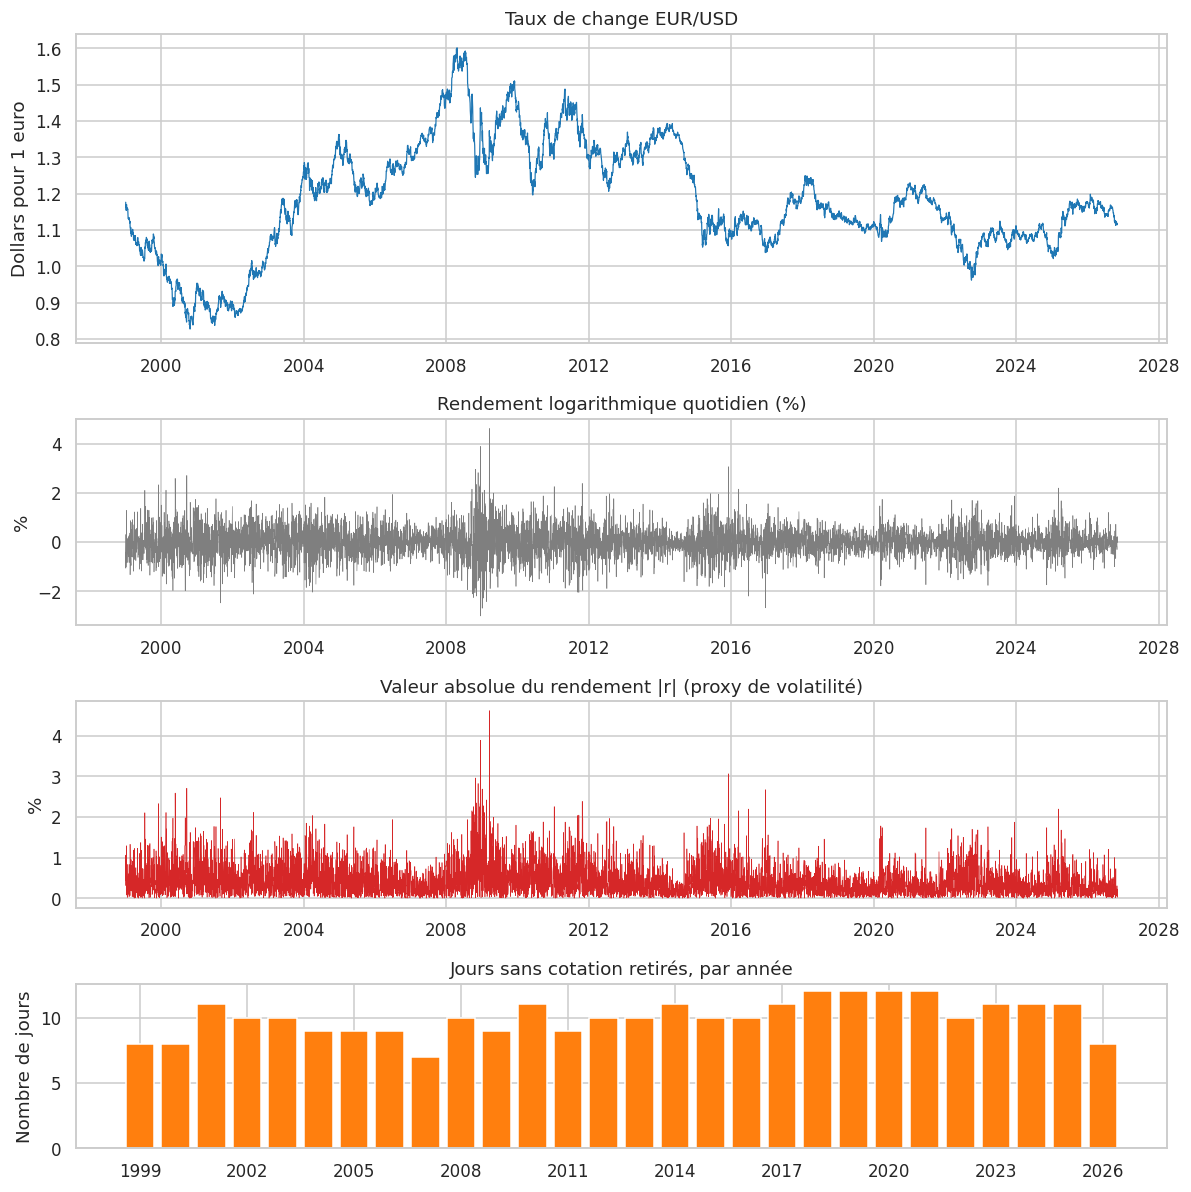

In [ ]:
jours = sql("""SELECT SUBSTR(date_obs, 1, 4) AS annee, COUNT(valeur) AS jours_cotes, COUNT(*) - COUNT(valeur) AS jours_manquants
FROM fred_jour GROUP BY annee ORDER BY annee;""")
rend = sql("SELECT date_obs, taux, r, abs_r FROM rendement")
rend["date_obs"] = pd.to_datetime(rend["date_obs"])

fig, axes = plt.subplots(4, 1, figsize=(11, 11), gridspec_kw={"height_ratios": [1.5, 1, 1, 0.8]})
axes[0].plot(rend["date_obs"], rend["taux"], lw=0.8, color="tab:blue")
axes[0].set_title("Taux de change EUR/USD"); axes[0].set_ylabel("Dollars pour 1 euro")
axes[1].plot(rend["date_obs"], rend["r"], lw=0.4, color="tab:grey")
axes[1].set_title("Rendement logarithmique quotidien (%)"); axes[1].set_ylabel("%")
axes[2].plot(rend["date_obs"], rend["abs_r"], lw=0.4, color="tab:red")
axes[2].set_title("Valeur absolue du rendement |r| (proxy de volatilité)"); axes[2].set_ylabel("%")
axes[3].bar(jours["annee"], jours["jours_manquants"], color="tab:orange")
axes[3].set_xticks(range(0, len(jours), 3)); axes[3].set_xticklabels(jours["annee"][::3])
axes[3].set_title("Jours sans cotation retirés, par année"); axes[3].set_ylabel("Nombre de jours")
plt.tight_layout(); plt.show()

**Lecture.** Après retrait des jours sans cotation, il reste 6 978 rendements. Le rendement absolu moyen est de 0,42 % par jour et l'écart-type de 0,57 % ; 64 rendements sont exactement nuls (cours inchangé à la 4e décimale). Les plus gros mouvements datent de la crise financière (+4,6 % le 19 mars 2009, +3,9 % le 17 décembre 2008) puis de décisions de banques centrales (+3,1 % le 3 décembre 2015 après la BCE, −2,7 % le 15 décembre 2016 après la Fed). Les graphiques montrent des grappes nettes : les grands mouvements se concentrent en 2008-2009, 2010-2012, 2015 et 2020.

## 4. Exploration : regroupement de la volatilité et régimes

Si le passé aide à prévoir l'amplitude, c'est parce que la volatilité est **persistante** : les grands mouvements arrivent en grappes (« volatility clustering »). On le vérifie de deux façons : par l'autocorrélation de $r$ (attendue nulle) comparée à celle de $|r|$ (attendue positive et lente à décroître), calculée en SQL pour l'ordre 1 puis tracée jusqu'à 60 jours, et par des statistiques par **régime de marché**. Les régimes sont définis en SQL (table `regimes`) à partir de l'histoire du marché. **Attention :** ils sont définis *après coup*. Ils servent à décrire et à diagnostiquer les erreurs, jamais à expliquer : à la date $t$, on ne sait pas encore dans quel régime on se trouve. Les autocorrélations n'utilisent que la période d'entraînement (avant 2015).

In [ ]:
con.executescript("""-- Régimes définis APRÈS COUP : pour décrire et diagnostiquer, jamais comme variable explicative.
DROP TABLE IF EXISTS regimes;
CREATE TABLE regimes (code INTEGER PRIMARY KEY, libelle TEXT, debut TEXT, fin TEXT);
INSERT INTO regimes VALUES
 (1,  'Lancement de l''euro',            '1999-01', '2001-12'),
 (2,  'Remontée de l''euro',             '2002-01', '2008-06'),
 (3,  'Crise financière mondiale',       '2008-07', '2009-06'),
 (4,  'Crise de la dette en zone euro',  '2009-07', '2012-12'),
 (5,  'Calme relatif',                   '2013-01', '2014-06'),
 (6,  'Divergence BCE / Fed',            '2014-07', '2016-12'),
 (7,  'Faible volatilité',               '2017-01', '2020-01'),
 (8,  'Covid-19',                        '2020-02', '2020-12'),
 (9,  'Inflation et guerre en Ukraine',  '2021-01', '2023-06'),
 (10, 'Période récente',                 '2023-07', '2026-12');""")
tab_regimes = sql("""SELECT g.code, g.libelle, g.debut, g.fin,
       COUNT(*)                                   AS nb_jours,
       ROUND(AVG(r.abs_r), 3)                     AS abs_r_moyen_pct,
       ROUND(SQRT(AVG(r.r2)) * SQRT(252.0), 1)    AS vol_annualisee_pct,
       ROUND(MAX(r.abs_r), 2)                     AS max_abs_r_pct
FROM rendement r JOIN regimes g ON SUBSTR(r.date_obs, 1, 7) BETWEEN g.debut AND g.fin
GROUP BY g.code ORDER BY g.code;""")
display(tab_regimes)

print(sql("""-- Autocorrélation d'ordre 1 de r et de |r| (entraînement : avant 2015)
WITH p AS (
    SELECT r, abs_r, LAG(r) OVER (ORDER BY date_obs) AS r_1, LAG(abs_r) OVER (ORDER BY date_obs) AS a_1
    FROM rendement WHERE date_obs < '2015-01-01'
)
SELECT ROUND((AVG(r*r_1) - AVG(r)*AVG(r_1)) / SQRT((AVG(r*r) - AVG(r)*AVG(r)) * (AVG(r_1*r_1) - AVG(r_1)*AVG(r_1))), 3) AS autocorr_r_lag1,
       ROUND((AVG(abs_r*a_1) - AVG(abs_r)*AVG(a_1)) / SQRT((AVG(abs_r*abs_r) - AVG(abs_r)*AVG(abs_r)) * (AVG(a_1*a_1) - AVG(a_1)*AVG(a_1))), 3) AS autocorr_abs_r_lag1
FROM p WHERE r_1 IS NOT NULL;""").to_string(index=False))

,code,libelle,debut,fin,nb_jours,abs_r_moyen_pct,vol_annualisee_pct,max_abs_r_pct
0,1,Lancement de l'euro,1999-01,2001-12,753,0.508,10.5,2.71
1,2,Remontée de l'euro,2002-01,2008-06,1637,0.425,8.8,2.11
2,3,Crise financière mondiale,2008-07,2009-06,251,0.769,16.8,4.62
3,4,Crise de la dette en zone euro,2009-07,2012-12,879,0.506,10.4,2.38
4,5,Calme relatif,2013-01,2014-06,376,0.321,6.9,1.54
5,6,Divergence BCE / Fed,2014-07,2016-12,627,0.462,10.0,3.06
6,7,Faible volatilité,2017-01,2020-01,768,0.304,6.3,1.56
7,8,Covid-19,2020-02,2020-12,229,0.366,7.6,1.78
8,9,Inflation et guerre en Ukraine,2021-01,2023-06,624,0.377,8.0,1.76
9,10,Période récente,2023-07,2026-12,834,0.311,6.7,2.20


 autocorr_r_lag1  autocorr_abs_r_lag1
           0.008                0.031


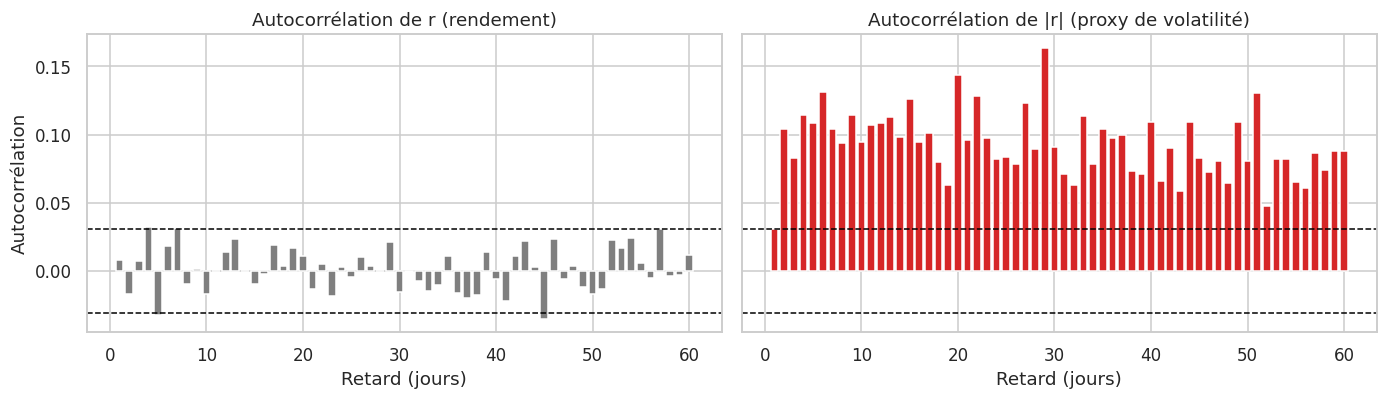

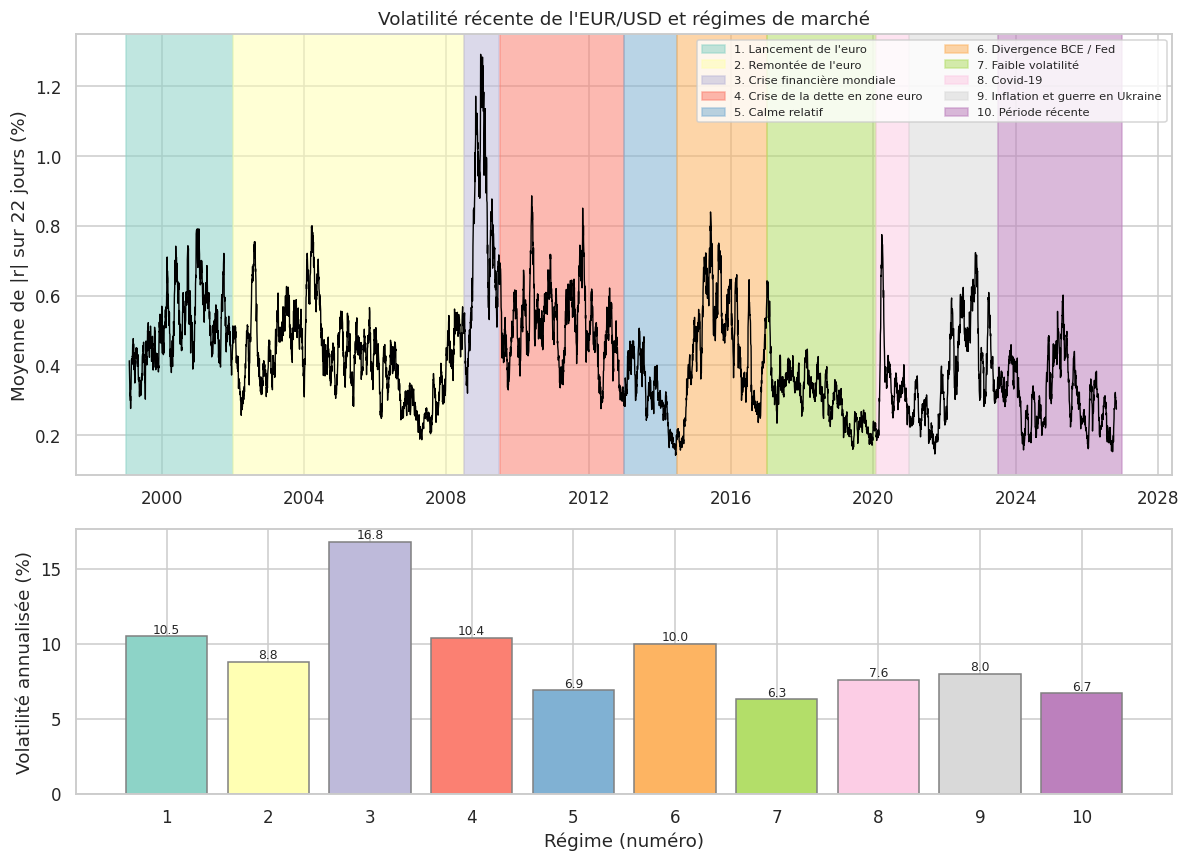

In [ ]:
tr0 = rend[rend["date_obs"] < "2015-01-01"].reset_index(drop=True)
seuil = 1.96 / np.sqrt(len(tr0))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, serie, nom, col in [(axes[0], tr0["r"], "r (rendement)", "tab:grey"), (axes[1], tr0["abs_r"], "|r| (proxy de volatilité)", "tab:red")]:
    lags = range(1, 61)
    ax.bar(lags, [serie.autocorr(lag=k) for k in lags], color=col)
    ax.axhline(seuil, color="black", ls="--", lw=1); ax.axhline(-seuil, color="black", ls="--", lw=1)
    ax.set_title(f"Autocorrélation de {nom}"); ax.set_xlabel("Retard (jours)")
axes[0].set_ylabel("Autocorrélation")
plt.tight_layout(); plt.show()

reg = tab_regimes.copy()
couleurs = sns.color_palette("Set3", len(reg))
m22 = rend.set_index("date_obs")["abs_r"].rolling(22).mean()
fig, axes = plt.subplots(2, 1, figsize=(11, 8), gridspec_kw={"height_ratios": [2, 1.2]})
ax = axes[0]
ax.plot(m22.index, m22.values, color="black", lw=0.9)
for (i, r_), c in zip(reg.iterrows(), couleurs):
    ax.axvspan(pd.Timestamp(r_["debut"] + "-01"), pd.Timestamp(r_["fin"] + "-01") + pd.offsets.MonthEnd(0),
               color=c, alpha=0.55, label=f'{r_["code"]}. {r_["libelle"]}')
ax.set_ylabel("Moyenne de |r| sur 22 jours (%)"); ax.set_title("Volatilité récente de l'EUR/USD et régimes de marché")
ax.legend(loc="upper right", fontsize=7.5, ncol=2)
ax = axes[1]
ax.bar(reg["code"].astype(str), reg["vol_annualisee_pct"], color=couleurs, edgecolor="grey")
for i, v in enumerate(reg["vol_annualisee_pct"]):
    ax.text(i, v + 0.2, f"{v:.1f}", ha="center", fontsize=8)
ax.set_xlabel("Régime (numéro)"); ax.set_ylabel("Volatilité annualisée (%)")
plt.tight_layout(); plt.show()

**Lecture.** Le rendement lui-même est quasi imprévisible (autocorrélation d'ordre 1 de 0,008). La valeur absolue est différente : son autocorrélation d'ordre 1 est faible (0,03, au niveau du seuil à 5 %), mais elle devient nettement positive aux retards suivants (environ 0,10 aux retards 2, 5 et 10, 0,13 à 22 jours, 0,09 à 60 jours) et décroît très lentement, ce qui est la signature de la mémoire longue de la volatilité. Conséquence pratique : une moyenne sur plusieurs semaines (`ma22`, `ma66`) devrait être plus utile que la valeur de la veille seule. Les régimes diffèrent surtout par la volatilité annualisée : environ 17 % pendant la crise financière de 2008-2009, 10 % pendant la crise de la dette et la divergence BCE / Fed, et seulement 6 à 7 % en 2017-2020 et depuis 2023.

## 5. Variables et découpage

La table `variables` contient, pour chaque jour $t$, les **retards des rendements absolus** `a0` à `a4` (`a0` = $|r_t|$), les moyennes de $|r|$ sur 5, 22 et 66 jours (`ma5`, `ma22`, `ma66` : semaine, mois, trimestre) et `hist_moy`, la **volatilité historique moyenne** : moyenne de tous les $|r|$ observés depuis 1999 jusqu'à $t$ (la référence). La cible est $|r_{t+1}|$ (`LEAD`), avec $r_{t+1}^2$ en plus pour la métrique QLIKE. **Précautions :** toutes les variables sont mesurées à la clôture de $t$ (fenêtres arrière seulement), les 65 premiers jours sont écartés pour que les moyennes mobiles soient complètes. Le **découpage est temporel** : entraînement si le jour prévu est avant 2015, test ensuite. Un découpage aléatoire serait une fuite d'information, car la volatilité d'un jour ressemble à celle de ses voisins. Le régime associé au jour prévu est joint pour le diagnostic uniquement.

In [ ]:
con.executescript("""-- Une ligne = un jour t ; uniquement de l'information connue à la clôture de t (LAG et fenêtres arrière).
-- Cible : |r| du jour ouvré suivant (LEAD). Jeu = 'train' si le jour prévu est avant 2015.
DROP TABLE IF EXISTS variables;
CREATE TABLE variables AS
WITH calc AS (
    SELECT date_obs, taux, r, abs_r, r2,
           ROW_NUMBER() OVER w0                                   AS n,
           abs_r                                                  AS a0,
           LAG(abs_r, 1) OVER w0                                  AS a1,
           LAG(abs_r, 2) OVER w0                                  AS a2,
           LAG(abs_r, 3) OVER w0                                  AS a3,
           LAG(abs_r, 4) OVER w0                                  AS a4,
           AVG(abs_r) OVER (ORDER BY date_obs ROWS BETWEEN 4  PRECEDING AND CURRENT ROW) AS ma5,
           AVG(abs_r) OVER (ORDER BY date_obs ROWS BETWEEN 21 PRECEDING AND CURRENT ROW) AS ma22,
           AVG(abs_r) OVER (ORDER BY date_obs ROWS BETWEEN 65 PRECEDING AND CURRENT ROW) AS ma66,
           AVG(abs_r) OVER (ORDER BY date_obs ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS hist_moy,
           LEAD(date_obs) OVER w0                                 AS date_cible,
           LEAD(abs_r)    OVER w0                                 AS cible,
           LEAD(r2)       OVER w0                                 AS cible_r2,
           LEAD(r)        OVER w0                                 AS cible_r
    FROM rendement
    WINDOW w0 AS (ORDER BY date_obs)
)
SELECT c.date_obs, c.taux, c.r, c.a0, c.a1, c.a2, c.a3, c.a4, c.ma5, c.ma22, c.ma66, c.hist_moy,
       c.date_cible, c.cible, c.cible_r2, c.cible_r,
       CASE WHEN c.date_cible < '2015-01-01' THEN 'train' ELSE 'test' END AS jeu,
       g.code AS regime_code, g.libelle AS regime
FROM calc c
LEFT JOIN regimes g ON SUBSTR(c.date_cible, 1, 7) BETWEEN g.debut AND g.fin
WHERE c.n >= 66            -- il faut 66 rendements pour la moyenne sur 66 jours
ORDER BY c.date_obs;""")
print(sql("""SELECT jeu, COUNT(*) AS nb_jours, MIN(date_obs) AS debut, MAX(date_obs) AS fin, COUNT(cible) AS nb_cibles
FROM variables GROUP BY jeu ORDER BY jeu DESC;""").to_string(index=False))
ref = sql("""-- Référence : prévoir |r| du lendemain par la moyenne historique connue à la date t
SELECT jeu, COUNT(*) AS nb_jours,
       ROUND(AVG((cible - hist_moy) * (cible - hist_moy)), 4) AS eqm
FROM variables WHERE cible IS NOT NULL GROUP BY jeu ORDER BY jeu DESC;""")
ref["rmse"] = np.sqrt(ref["eqm"]).round(4)
display(ref)
sql("SELECT date_obs, ROUND(a0,3) a0, ROUND(a1,3) a1, ROUND(ma5,3) ma5, ROUND(ma22,3) ma22, ROUND(ma66,3) ma66, ROUND(hist_moy,3) hist_moy, ROUND(cible,3) cible, jeu, regime FROM variables ORDER BY date_obs DESC LIMIT 5;")

  jeu  nb_jours      debut        fin  nb_cibles
train      3955 1999-04-08 2014-12-30       3955
 test      2958 2014-12-31 2026-10-30       2957


,jeu,nb_jours,eqm,rmse
0,train,3955,0.1793,0.4234
1,test,2957,0.1156,0.3400


,date_obs,a0,a1,ma5,ma22,ma66,hist_moy,cible,jeu,regime
0,2026-10-30,0.018,0.224,0.154,0.274,0.227,0.421,NaN,test,None
1,2026-10-29,0.224,0.036,0.174,0.286,0.230,0.421,0.018,test,Période récente
2,2026-10-28,0.036,0.305,0.141,0.289,0.228,0.421,0.224,test,Période récente
3,2026-10-27,0.305,0.188,0.157,0.298,0.229,0.421,0.036,test,Période récente
4,2026-10-26,0.188,0.116,0.137,0.293,0.229,0.421,0.305,test,Période récente


**Lecture.** L'entraînement compte 3 955 jours (avril 1999 à fin 2014) et le test 2 957 jours (janvier 2015 à octobre 2026) ; le tout dernier jour n'a pas de cible et sera écarté. La référence (volatilité historique moyenne) fait un RMSE de 0,42 % sur l'entraînement et de 0,34 % sur le test : c'est le niveau à battre. Elle a un défaut visible dès maintenant : la moyenne depuis 1999 (de 0,47 % en 2015 à 0,42 % en 2026) reste figée au-dessus de la volatilité récente (moyenne sur 22 jours autour de 0,3 %), car le change est devenu plus calme.

## 6. Le bruit du proxy |r|

C'est le **risque** principal de ce sujet. La valeur absolue d'un seul rendement est une mesure *très* bruitée de la volatilité : même si l'on connaissait parfaitement l'écart-type du jour, $|r|$ resterait aléatoire autour de lui. Si $r = \sigma z$ avec $z$ normal, l'erreur quadratique minimale sur $|r|$ vaut environ $0{,}6\,\sigma$, jamais zéro. On le mesure ici avec un **oracle** : la volatilité réalisée sur les 10 jours avant et les 10 jours après le jour cible (jour exclu), calculée en SQL. L'oracle utilise le futur : ce n'est **pas** un modèle, seulement un plafond de qualité. On en tire aussi le facteur $k = E|r| / \sqrt{E[r^2]}$, estimé sur l'entraînement, qui sert à convertir une prévision de $|r|$ en prévision de variance pour la métrique QLIKE (pour une loi normale $k=\sqrt{2/\pi}\approx 0{,}80$ ; les queues épaisses le font baisser).

k = 0.7414  (loi normale : 0.7979)
RMSE de l'oracle sur |r| (test) : 0.3165 %  | |r| moyen : 0.3598 %  | rapport : 0.88
Plafond théorique (loi normale) : 0.603 x sigma, soit environ 0.2944 %


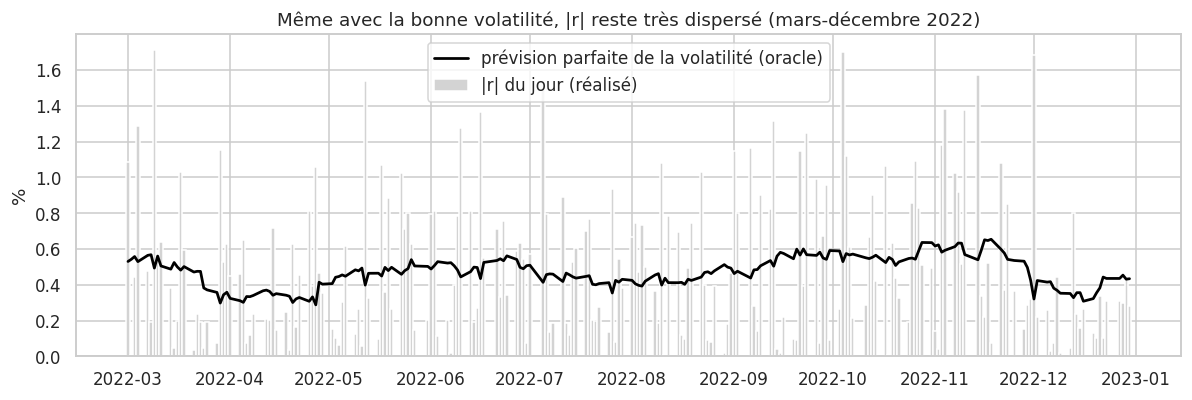

In [ ]:
k_df = sql("""-- Facteur de conversion k = E|r| / racine(E[r²]) sur l'entraînement uniquement
SELECT AVG(cible) / SQRT(AVG(cible_r2)) AS k FROM variables WHERE jeu = 'train' AND cible IS NOT NULL;""")
K = float(k_df.loc[0, "k"])
print(f"k = {K:.4f}  (loi normale : {np.sqrt(2/np.pi):.4f})")

oracle = sql("""-- Oracle (utilise le futur : plafond de qualité, pas un modèle) : volatilité réalisée sur 10 jours avant et 10 jours après,
-- jour exclu ; prévision de |r| = k * volatilité réalisée.
WITH fen AS (
    SELECT date_obs, abs_r,
           (SUM(r2) OVER w - r2) / 20.0 AS var_voisinage,
           COUNT(*) OVER w AS nb
    FROM rendement
    WINDOW w AS (ORDER BY date_obs ROWS BETWEEN 10 PRECEDING AND 10 FOLLOWING)
)
SELECT f.date_obs, f.abs_r, {k} * SQRT(f.var_voisinage) AS prevu_oracle
FROM fen f WHERE f.nb = 21 AND f.date_obs >= '2015-01-01';""".replace("{k}", repr(K)))
rmse_or = np.sqrt(((oracle["abs_r"] - oracle["prevu_oracle"]) ** 2).mean())
print(f"RMSE de l'oracle sur |r| (test) : {rmse_or:.4f} %  | |r| moyen : {oracle['abs_r'].mean():.4f} %  | rapport : {rmse_or/oracle['abs_r'].mean():.2f}")
print(f"Plafond théorique (loi normale) : {np.sqrt(1-2/np.pi):.3f} x sigma, soit environ {np.sqrt(1-2/np.pi)*np.sqrt((oracle['abs_r']**2).mean()):.4f} %")

z = oracle[(oracle["date_obs"] >= "2022-03-01") & (oracle["date_obs"] <= "2022-12-31")].copy()
z["date_obs"] = pd.to_datetime(z["date_obs"])
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(z["date_obs"], z["abs_r"], width=1.0, color="lightgrey", label="|r| du jour (réalisé)")
ax.plot(z["date_obs"], z["prevu_oracle"], color="black", lw=1.8, label="prévision parfaite de la volatilité (oracle)")
ax.set_title("Même avec la bonne volatilité, |r| reste très dispersé (mars-décembre 2022)"); ax.set_ylabel("%"); ax.legend()
plt.tight_layout(); plt.show()

**Lecture.** Le facteur de conversion estimé est k = 0,74, inférieur à 0,80 (valeur normale) : les queues épaisses des rendements rendent |r| plus petit, en moyenne, que ne le supposerait une loi normale. Surtout, l'oracle, qui connaît la volatilité voisine des 20 autres jours et utilise donc le futur, ne descend qu'à un RMSE de 0,32 % sur |r|, soit 88 % du |r| moyen (0,36 %), pour un plafond théorique normal d'environ 0,29 %. Autrement dit, même une connaissance quasi parfaite de la volatilité laisse une erreur énorme sur |r| : le **plafond de qualité est proche de la référence**, et c'est ce qui limite tout gain en RMSE. Une erreur de 0,32 % n'est donc pas « mauvaise » en soi, et une erreur plus faible ne prouve pas que le modèle prévoit bien. Le graphique le montre : les barres grises (|r| quotidiens) sont très dispersées autour de la courbe noire.

## 7. Modèles

On compare quatre modèles de prévision de $E|r_{t+1}|$ : la **volatilité historique moyenne** (référence, calculée en SQL), la **régression linéaire** avec retards (`a0`..`a4`, `ma5`, `ma22`, `ma66`), le **gradient boosting** avec les mêmes variables, et un **GARCH(1,1)** à lois de Student (comparaison avancée, estimé sur les rendements seuls). L'évaluation est **walk-forward** : le modèle est réestimé tous les 21 jours ouvrés (environ un mois) sur les jours dont la cible est déjà connue, puis prévoit les 21 jours suivants. Les hyperparamètres du boosting sont choisis **une seule fois** par `TimeSeriesSplit` sur l'entraînement initial, jamais sur le test. Pour le GARCH, les paramètres sont réestimés au même rythme et la variance du lendemain est mise à jour chaque jour par la récurrence $\sigma^2_{t+1} = \omega + \alpha r_t^2 + \beta \sigma^2_t$ ; sa prévision de $|r|$ est $k\,\sigma_{t+1}$. Enfin, toute prévision de $|r|$ est bornée en bas à 0,05 % (une volatilité prévue négative n'a pas de sens, et la QLIKE exige une variance positive), puis convertie en variance $h = (|r|_{prévu}/k)^2$.

In [ ]:
dat = sql("SELECT * FROM variables WHERE cible IS NOT NULL ORDER BY date_obs")
dat["date"] = pd.to_datetime(dat["date_obs"])
FEATS = ["a0", "a1", "a2", "a3", "a4", "ma5", "ma22", "ma66"]
init = dat[dat["jeu"] == "train"]
print("Entraînement initial :", len(init), "jours ; test :", (dat["jeu"] == "test").sum(), "jours")

tscv = TimeSeriesSplit(n_splits=5)
g_b = GridSearchCV(GradientBoostingRegressor(learning_rate=0.05, subsample=0.8, min_samples_leaf=50, random_state=42),
                   {"max_depth": [1, 2, 3], "n_estimators": [50, 150, 300]}, cv=tscv,
                   scoring="neg_mean_squared_error").fit(init[FEATS], init["cible"])
PARAMS_GB = g_b.best_params_
print("Hyperparamètres du gradient boosting :", PARAMS_GB)

Entraînement initial : 3955 jours ; test : 2957 jours
Hyperparamètres du gradient boosting : {'max_depth': 1, 'n_estimators': 150}


In [ ]:
PAS, PLANCHER = 21, 0.05
MODELES = ["Volatilité historique moyenne", "Régression linéaire", "Gradient boosting", "GARCH(1,1)"]

def walk_forward(donnees):
    """Prévisions à un jour, réestimation toutes les PAS séances sur les cibles déjà connues."""
    idx_test = donnees.index[donnees["jeu"] == "test"]
    p = {m: np.full(len(idx_test), np.nan) for m in MODELES}
    r_tous = donnees["r"].to_numpy()
    for deb in range(0, len(idx_test), PAS):
        bloc = idx_test[deb:deb + PAS]; i0 = bloc[0]
        passe = donnees.iloc[:i0]                       # cibles connues à la clôture de i0 : lignes < i0
        x = donnees.loc[bloc, FEATS]
        sl = slice(deb, deb + len(bloc))
        p["Volatilité historique moyenne"][sl] = donnees.loc[bloc, "hist_moy"].to_numpy()
        p["Régression linéaire"][sl] = LinearRegression().fit(passe[FEATS], passe["cible"]).predict(x)
        p["Gradient boosting"][sl] = GradientBoostingRegressor(learning_rate=0.05, subsample=0.8, min_samples_leaf=50,
                                                               random_state=42, **PARAMS_GB).fit(passe[FEATS], passe["cible"]).predict(x)
        # GARCH(1,1) estimé sur les rendements connus jusqu'à la clôture de i0 (inclus)
        res = arch_model(r_tous[:i0 + 1], mean="Zero", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
        om, al, be = res.params["omega"], res.params["alpha[1]"], res.params["beta[1]"]
        s2 = float(res.conditional_volatility[-1]) ** 2   # variance de r_i0 sachant le passé
        for j, i in enumerate(bloc):
            s2 = om + al * r_tous[i] ** 2 + be * s2        # variance prévue pour le jour suivant
            p["GARCH(1,1)"][deb + j] = K * np.sqrt(s2)
    t = donnees.loc[idx_test].copy()
    for m in MODELES:
        t[m] = np.maximum(p[m], PLANCHER)
        t["h::" + m] = (t[m] / K) ** 2
    return t

test = walk_forward(dat)
print("Prévisions calculées pour", len(test), "jours, de", test["date_cible"].min(), "à", test["date_cible"].max())

Prévisions calculées pour 2957 jours, de 2015-01-02 à 2026-10-30


**Lecture.** Le boosting retient une profondeur de 1 (arbres à une seule coupure) et 150 arbres : le meilleur réglage est le plus simple, ce qui indique que la relation entre le passé et la volatilité à venir est presque additive et lisse, sans interactions complexes. On peut s'attendre à ce que le boosting fasse à peu près comme la régression linéaire. Les prévisions sont calculées pour les 2 957 jours du test.

## 8. Résultats

Cette section calcule le **RMSE** de chaque modèle sur $|r_{t+1}|$ (en points de pourcentage) et la **QLIKE** sur la variance. La QLIKE est la perte adaptée à la volatilité : pour une variance prévue $h$ et un proxy $\hat\sigma^2 = r^2$, on utilise $\ln h + r^2/h$ (équivalente, à une constante près qui ne dépend pas du modèle, à la forme $r^2/h - \ln(r^2/h) - 1$, mais finie même quand $r = 0$, ce qui arrive quand le cours est inchangé). Elle pénalise davantage une volatilité sous-estimée qu'une volatilité surestimée, et elle reste un bon critère de comparaison même quand le proxy est bruité, ce que le RMSE tolère moins bien. **Plus c'est bas, mieux c'est**, pour les deux. Les deux métriques sont comparées à la référence : `RMSE / référence` inférieur à 1 signifie meilleur, `QLIKE − référence` négatif signifie meilleur. Les mêmes erreurs sont ensuite recalculées en SQL à partir d'une table `previsions` pour vérifier la cohérence.

In [ ]:
def metriques(t, modeles=MODELES):
    lignes = []
    for m in modeles:
        e = t["cible"] - t[m]
        h = t["h::" + m]
        lignes.append({"Modèle": m, "RMSE (%)": np.sqrt((e ** 2).mean()),
                       "QLIKE": (np.log(h) + t["cible_r2"] / h).mean()})
    r = pd.DataFrame(lignes)
    r["RMSE / référence"] = r["RMSE (%)"] / r.loc[0, "RMSE (%)"]
    r["QLIKE − référence"] = r["QLIKE"] - r.loc[0, "QLIKE"]
    return r

resultats = metriques(test)
resultats.round(4)

,Modèle,RMSE (%),QLIKE,RMSE / référence,QLIKE − référence
0,Volatilité historique moyenne,0.3400,-0.3669,1.0000,0.0000
1,Régression linéaire,0.3173,-0.5429,0.9335,-0.1761
2,Gradient boosting,0.3173,-0.5392,0.9335,-0.1723
3,"GARCH(1,1)",0.3154,-0.5592,0.9279,-0.1923


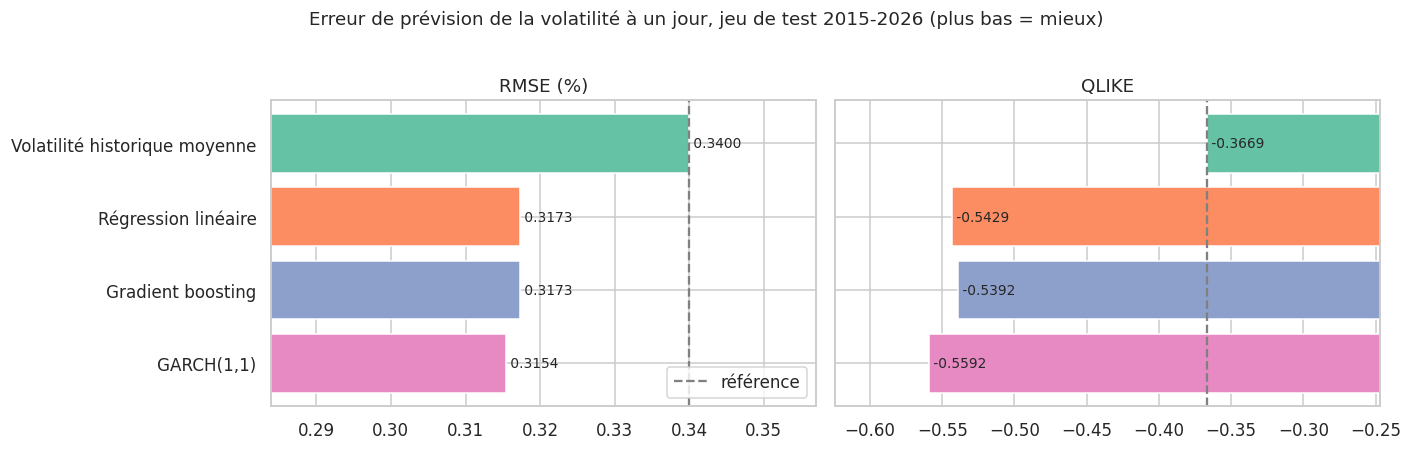

,modele,nb_jours,rmse,qlike
0,"GARCH(1,1)",2957,0.3154,-0.5592
1,Régression linéaire,2957,0.3173,-0.5429
2,Gradient boosting,2957,0.3173,-0.5392
3,Volatilité historique moyenne,2957,0.3400,-0.3669


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
coul = sns.color_palette("Set2", len(MODELES))
for ax, metrique in zip(axes, ["RMSE (%)", "QLIKE"]):
    v = resultats[metrique]
    ax.barh(resultats["Modèle"], v, color=coul)
    ax.axvline(v.iloc[0], color="grey", ls="--", label="référence")
    for i, x in enumerate(v):
        ax.text(x, i, f" {x:.4f}", va="center", fontsize=9)
    ax.invert_yaxis(); ax.set_title(metrique)
    if metrique == "QLIKE":
        ax.set_xlim(v.min() - 0.08 * abs(v.min()) - 0.02, v.max() + 0.12)
    else:
        ax.set_xlim(v.min() * 0.9, v.max() * 1.05)
axes[1].set_yticklabels([]); axes[0].legend(loc="lower right")
plt.suptitle("Erreur de prévision de la volatilité à un jour, jeu de test 2015-2026 (plus bas = mieux)", y=1.02, fontsize=12)
plt.tight_layout(); plt.show()

# Contrôle : mêmes métriques recalculées en SQL à partir de la table 'previsions' (format long)
long = pd.concat([pd.DataFrame({"date_cible": test["date_cible"], "modele": m, "cible": test["cible"],
                                "cible_r2": test["cible_r2"], "prevu": test[m], "h": test["h::" + m]}) for m in MODELES])
long.to_sql("previsions", con, if_exists="replace", index=False)
q = sql("""SELECT modele,
       COUNT(*)                                                AS nb_jours,
       ROUND(SQRT(AVG((cible - prevu) * (cible - prevu))), 4)  AS rmse,
       ROUND(AVG(LN(h) + cible_r2 / h), 4)                     AS qlike
FROM previsions GROUP BY modele ORDER BY qlike;""")
q

**Lecture.** Les trois modèles qui utilisent le passé battent la référence. En RMSE, la régression linéaire et le gradient boosting font 0,317 % (rapport 0,934 : environ 7 % d'erreur en moins) et le GARCH 0,315 % (rapport 0,928). En QLIKE, qui distingue mieux les modèles, l'écart avec la référence est de −0,176 (linéaire), −0,172 (boosting) et −0,192 (GARCH) : le GARCH est le meilleur, devant le linéaire et le boosting, très proches. Le gain en RMSE paraît modeste parce que le bruit de |r| (section 6) écrase tout : pas parce que les modèles prévoient mal la volatilité. Le calcul SQL redonne exactement les mêmes chiffres.

## 9. Volatilité prévue contre réalisée

C'est le graphique central du livrable. Le premier panneau superpose, sur tout le test, la volatilité prévue la veille par chaque modèle à la volatilité **réalisée** : les points gris sont les $|r|$ quotidiens (bruités), la courbe noire est leur moyenne centrée sur 22 jours (une meilleure image de la volatilité réellement observée, **utilisée uniquement pour l'affichage**, jamais pour l'évaluation). Les deux panneaux du milieu zooment sur deux épisodes de tension. Un deuxième graphique trace la **calibration** : on range les jours par décile de volatilité prévue et on compare, dans chaque décile, la prévision moyenne au $|r|$ moyen réalisé ; sur la diagonale, la prévision est juste en moyenne. Enfin, on suit le RMSE glissant sur 250 jours. Les prévisions faites à la clôture de $t$ portent sur $t+1$ : on les place donc à la date du jour prévu.

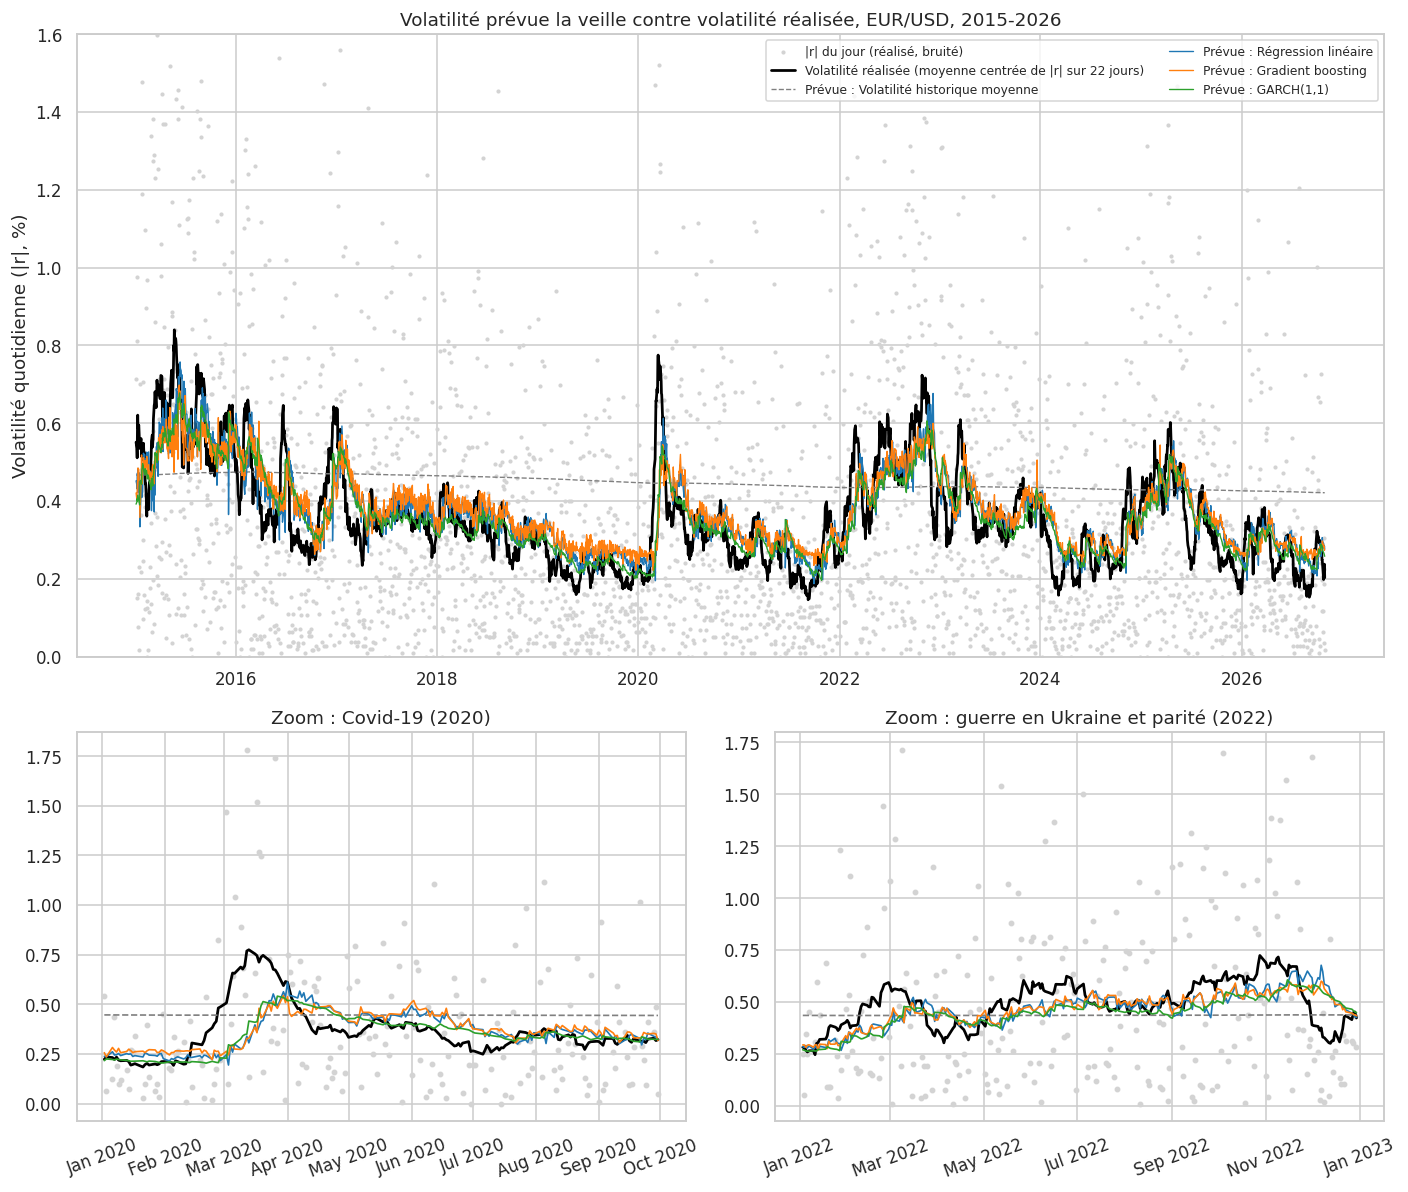

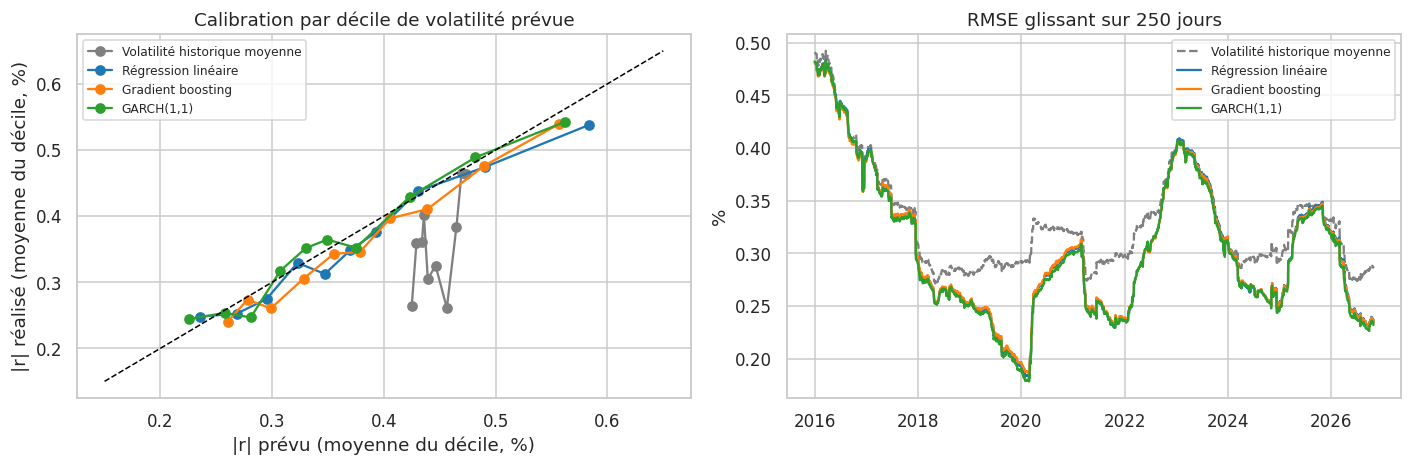

In [ ]:
test["date_c"] = pd.to_datetime(test["date_cible"])
reel_lisse = test["cible"].rolling(22, center=True, min_periods=11).mean()
styles = {"Volatilité historique moyenne": ("grey", "--"), "Régression linéaire": ("tab:blue", "-"),
          "Gradient boosting": ("tab:orange", "-"), "GARCH(1,1)": ("tab:green", "-")}

fig = plt.figure(figsize=(13, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1.6, 1])
ax = fig.add_subplot(gs[0, :])
ax.scatter(test["date_c"], test["cible"], s=3, color="lightgrey", label="|r| du jour (réalisé, bruité)")
ax.plot(test["date_c"], reel_lisse, color="black", lw=1.8, label="Volatilité réalisée (moyenne centrée de |r| sur 22 jours)")
for m, (c, ls) in styles.items():
    ax.plot(test["date_c"], test[m], color=c, ls=ls, lw=0.9, label=f"Prévue : {m}")
ax.set_ylim(0, 1.6); ax.set_ylabel("Volatilité quotidienne (|r|, %)")
ax.set_title("Volatilité prévue la veille contre volatilité réalisée, EUR/USD, 2015-2026"); ax.legend(ncol=2, fontsize=8, loc="upper right")
for pos, (d1, d2, titre) in zip([(1, 0), (1, 1)], [("2020-01-01", "2020-09-30", "Zoom : Covid-19 (2020)"), ("2022-01-01", "2022-12-31", "Zoom : guerre en Ukraine et parité (2022)")]):
    ax = fig.add_subplot(gs[pos])
    s = test[(test["date_c"] >= d1) & (test["date_c"] <= d2)]
    ax.scatter(s["date_c"], s["cible"], s=8, color="lightgrey")
    ax.plot(s["date_c"], reel_lisse.loc[s.index], color="black", lw=1.8)
    for m, (c, ls) in styles.items():
        ax.plot(s["date_c"], s[m], color=c, ls=ls, lw=1.1)
    ax.set_title(titre); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
for m, (c, ls) in styles.items():
    d = pd.DataFrame({"p": test[m].values, "y": test["cible"].values})
    d["dec"] = pd.qcut(d["p"].rank(method="first"), 10, labels=False)
    g = d.groupby("dec").mean()
    ax.plot(g["p"], g["y"], "o-", color=c, label=m)
lim = [0.15, 0.65]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlabel("|r| prévu (moyenne du décile, %)"); ax.set_ylabel("|r| réalisé (moyenne du décile, %)")
ax.set_title("Calibration par décile de volatilité prévue"); ax.legend(fontsize=8)
ax = axes[1]
for m, (c, ls) in styles.items():
    ax.plot(test["date_c"], ((test["cible"] - test[m]) ** 2).rolling(250).mean().pow(0.5), color=c, ls=ls, label=m)
ax.set_title("RMSE glissant sur 250 jours"); ax.set_ylabel("%"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lecture.** Les trois modèles suivent bien les mouvements lents de la volatilité réalisée (haute en 2015, basse en 2018-2019, remontée en 2022-2023, retour au calme en 2024-2026), alors que la référence reste figée autour de 0,45 % et surestime la volatilité pendant les périodes calmes. La calibration le confirme : les modèles s'alignent sur la diagonale sur toute l'étendue de leurs déciles de prévision (de 0,23 % à 0,58 %), alors que les déciles de la référence ne discriminent rien (prévu presque constant, réalisé de 0,26 à 0,38 %). En revanche, les modèles **réagissent après le choc, pas avant** : en mars 2020, la volatilité réalisée atteint environ 0,77 % alors que les prévisions restent autour de 0,25 % jusqu'au début du choc, puis plafonnent vers 0,5 % ; en 2022, ils sous-estiment les poussées de février-mars et de septembre-novembre. Le RMSE glissant est dominé par le niveau de la volatilité (il baisse en période calme, monte en 2016, 2020, 2023 et 2025) plus que par le modèle.

## 10. Régimes et robustesse

Une erreur moyenne globale peut cacher des périodes très différentes. Cette section calcule le RMSE et la QLIKE de chaque modèle **par régime de marché**, puis teste la **robustesse** de la conclusion : en excluant la pandémie (février à juin 2020), en excluant le 1 % de jours aux plus fortes erreurs de la référence, et en séparant le test en trois sous-périodes (2015-2019, 2020-2022, 2023-2026). Si un modèle ne bat pas la référence sur l'ensemble mais la bat dans un cas particulier, ce tableau le fait apparaître.

RMSE (%) par régime


,Volatilité historique moyenne,Régression linéaire,Gradient boosting,"GARCH(1,1)",nb_jours
Groupe,,,,,
06. Divergence BCE / Fed,0.444,0.437,0.436,0.438,502
07. Faible volatilité,0.294,0.248,0.250,0.245,768
08. Covid-19,0.322,0.313,0.314,0.310,229
09. Inflation et guerre en Ukraine,0.345,0.327,0.326,0.325,624
10. Période récente,0.307,0.280,0.279,0.278,834


QLIKE par régime


,Volatilité historique moyenne,Régression linéaire,Gradient boosting,"GARCH(1,1)"
Groupe,,,,
06. Divergence BCE / Fed,0.195,0.166,0.160,0.177
07. Faible volatilité,-0.555,-0.876,-0.852,-0.915
08. Covid-19,-0.379,-0.429,-0.417,-0.455
09. Inflation et guerre en Ukraine,-0.315,-0.459,-0.455,-0.467
10. Période récente,-0.567,-0.757,-0.768,-0.772


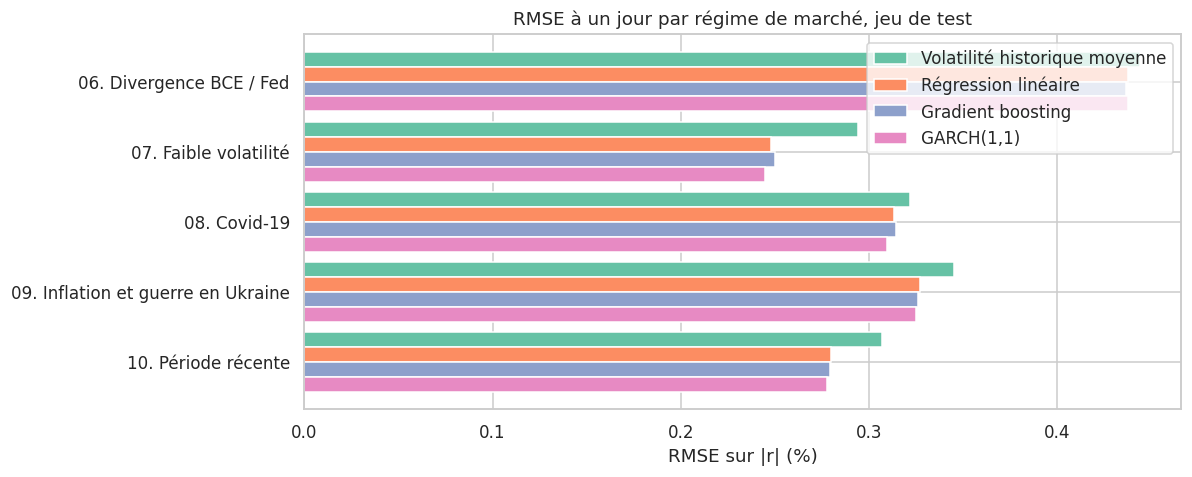

In [ ]:
test["Régime"] = test["regime_code"].astype(int).astype(str).str.zfill(2) + ". " + test["regime"]
def par_groupe(t, cle):
    lignes = []
    for k_, g in t.groupby(cle):
        mm = metriques(g)
        ligne = {"Groupe": k_, "nb_jours": len(g)}
        for _, row in mm.iterrows():
            ligne[("RMSE", row["Modèle"])] = row["RMSE (%)"]; ligne[("QLIKE", row["Modèle"])] = row["QLIKE"]
        lignes.append(ligne)
    return pd.DataFrame(lignes).set_index("Groupe")
par_regime = par_groupe(test, "Régime")
rm = par_regime[[c for c in par_regime.columns if c != "nb_jours" and c[0] == "RMSE"]]; rm.columns = MODELES
ql = par_regime[[c for c in par_regime.columns if c != "nb_jours" and c[0] == "QLIKE"]]; ql.columns = MODELES
print("RMSE (%) par régime"); display(rm.assign(nb_jours=par_regime["nb_jours"]).round(3))
print("QLIKE par régime"); display(ql.round(3))

ax = rm.plot.barh(figsize=(11, 4.5), width=0.85); ax.invert_yaxis()
ax.set_xlabel("RMSE sur |r| (%)"); ax.set_ylabel(""); ax.set_title("RMSE à un jour par régime de marché, jeu de test")
plt.tight_layout(); plt.show()

In [ ]:
def tab_rob(t, nom):
    r = metriques(t).set_index("Modèle")
    return r[["RMSE (%)"]].rename(columns={"RMSE (%)": nom}), r[["QLIKE"]].rename(columns={"QLIKE": nom})

err_ref = (test["cible"] - test[MODELES[0]]).abs()
sans_covid = test[~test["date_cible"].between("2020-02-01", "2020-06-30")]
sans_top = test.drop(err_ref.nlargest(int(0.01 * len(test))).index)
test["periode"] = np.where(test["date_cible"] < "2020-01-01", "2015-2019", np.where(test["date_cible"] < "2023-01-01", "2020-2022", "2023-2026"))
cas = [("Test complet", test), ("Sans fév.-juin 2020", sans_covid), ("Sans 1 % plus grosses erreurs", sans_top)] + \
      [(p_, test[test["periode"] == p_]) for p_ in ["2015-2019", "2020-2022", "2023-2026"]]
res_rob = [tab_rob(t, n) for n, t in cas]
rob_rmse = pd.concat([a for a, b in res_rob], axis=1); rob_qlike = pd.concat([b for a, b in res_rob], axis=1)
print("RMSE (%)"); display(rob_rmse.round(4))
print("QLIKE"); display(rob_qlike.round(4))
print("Nombre de situations (sur", rob_rmse.shape[1], ") où le modèle bat la référence :")
print(pd.DataFrame({"en RMSE": rob_rmse.drop(index=MODELES[0]).lt(rob_rmse.loc[MODELES[0]]).sum(axis=1),
                    "en QLIKE": rob_qlike.drop(index=MODELES[0]).lt(rob_qlike.loc[MODELES[0]]).sum(axis=1)}).to_string())

RMSE (%)


,Test complet,Sans fév.-juin 2020,Sans 1 % plus grosses erreurs,2015-2019,2020-2022,2023-2026
Modèle,,,,,,
Volatilité historique moyenne,0.3400,0.3389,0.3109,0.3619,0.3404,0.3087
Régression linéaire,0.3173,0.3149,0.2864,0.3380,0.3189,0.2868
Gradient boosting,0.3173,0.3149,0.2858,0.3384,0.3189,0.2862
"GARCH(1,1)",0.3154,0.3132,0.2833,0.3368,0.3175,0.2834


QLIKE


,Test complet,Sans fév.-juin 2020,Sans 1 % plus grosses erreurs,2015-2019,2020-2022,2023-2026
Modèle,,,,,,
Volatilité historique moyenne,-0.3669,-0.3756,-0.4526,-0.2489,-0.3539,-0.5306
Régression linéaire,-0.5429,-0.5637,-0.6370,-0.4444,-0.5147,-0.6933
Gradient boosting,-0.5392,-0.5598,-0.6352,-0.4336,-0.5048,-0.7035
"GARCH(1,1)",-0.5592,-0.5791,-0.6630,-0.4630,-0.5222,-0.7134


Nombre de situations (sur 6 ) où le modèle bat la référence :
                     en RMSE  en QLIKE
Modèle                                
Régression linéaire        6         6
Gradient boosting          6         6
GARCH(1,1)                 6         6


**Lecture.** L'erreur dépend davantage du régime que du modèle : de 0,24 % de RMSE en période de faible volatilité (2017-2020) à 0,44 % lors de la divergence BCE / Fed (2015-2016). Le gain des modèles est le plus net quand la volatilité est basse et stable (RMSE de 0,29 % à 0,25 % pour la régression linéaire en 2017-2020, contre 0,31 % à 0,28 % depuis 2023) et le plus faible dans les épisodes de choc (de 0,444 % à 0,437 % en 2015-2016, de 0,322 % à 0,313 % pour le Covid). Les trois modèles battent la référence dans les six situations testées, en RMSE comme en QLIKE, y compris sans le Covid et sans les 1 % de jours les plus mal prévus. Le GARCH est le meilleur en QLIKE dans quatre régimes sur cinq (le boosting le devance légèrement en 2015-2016).

## 11. Tests statistiques

Un écart de RMSE ou de QLIKE entre deux modèles est-il réel ou dû au hasard ? Trois outils répondent. (1) Un **test de Diebold-Mariano** compare les pertes (erreur quadratique, puis QLIKE) jour par jour : les pertes de volatilité étant très autocorrélées, l'écart-type utilise une correction de Newey-West (10 retards), plus exigeante qu'un test naïf. (2) Un **bootstrap par blocs** (blocs de 22 jours, pour respecter l'autocorrélation) donne un intervalle de confiance à 95 % du rapport de RMSE et de la différence de QLIKE avec la référence. (3) Un contrôle de **direction** : la prévision de volatilité dit *combien* le change va bouger, pas *dans quel sens* ; on vérifie qu'elle ne contient aucune information sur le signe du rendement, pour ne pas confondre une erreur faible sur $|r|$ avec une bonne prévision de direction.

In [ ]:
def dm_hac(perte_a, perte_b, lag=10):
    """Diebold-Mariano avec variance de long terme de Newey-West. d < 0 : a fait mieux que b."""
    d = np.asarray(perte_a - perte_b, dtype=float); n = len(d); dc = d - d.mean()
    lrv = (dc @ dc) / n
    for j in range(1, lag + 1):
        lrv += 2 * (1 - j / (lag + 1)) * (dc[j:] @ dc[:-j]) / n
    stat = d.mean() / np.sqrt(lrv / n)
    return stat, 2 * (1 - stats.norm.cdf(abs(stat)))

def pertes(m):
    e2 = (test["cible"] - test[m]) ** 2
    ql = np.log(test["h::" + m]) + test["cible_r2"] / test["h::" + m]
    return {"Erreur quadratique": e2, "QLIKE": ql}

paires = [(m, MODELES[0]) for m in MODELES[1:]] + [("Gradient boosting", "Régression linéaire"),
          ("GARCH(1,1)", "Régression linéaire"), ("GARCH(1,1)", "Gradient boosting")]
lignes = []
for a, b in paires:
    for nom_perte in ["Erreur quadratique", "QLIKE"]:
        s, p = dm_hac(pertes(a)[nom_perte], pertes(b)[nom_perte])
        lignes.append({"Comparaison": f"{a} contre {b}", "Perte": nom_perte, "statistique": round(s, 2), "p-value": round(p, 4)})
tab_dm = pd.DataFrame(lignes)
tab_dm

,Comparaison,Perte,statistique,p-value
0,Régression linéaire contre Volatilité historiq...,Erreur quadratique,-8.93,0.0000
1,Régression linéaire contre Volatilité historiq...,QLIKE,-8.15,0.0000
2,Gradient boosting contre Volatilité historique...,Erreur quadratique,-9.72,0.0000
3,Gradient boosting contre Volatilité historique...,QLIKE,-8.86,0.0000
4,"GARCH(1,1) contre Volatilité historique moyenne",Erreur quadratique,-9.88,0.0000
5,"GARCH(1,1) contre Volatilité historique moyenne",QLIKE,-8.28,0.0000
6,Gradient boosting contre Régression linéaire,Erreur quadratique,-0.03,0.9791
7,Gradient boosting contre Régression linéaire,QLIKE,0.86,0.3889
8,"GARCH(1,1) contre Régression linéaire",Erreur quadratique,-2.69,0.0071
9,"GARCH(1,1) contre Régression linéaire",QLIKE,-2.69,0.0072


Rapport de RMSE (modèle / référence)


,"2,5 %",médiane,"97,5 %"
Régression linéaire,0.911,0.933,0.953
Gradient boosting,0.912,0.932,0.952
"GARCH(1,1)",0.905,0.927,0.947


Différence de QLIKE (modèle − référence)


,"2,5 %",médiane,"97,5 %"
Régression linéaire,-0.2271,-0.1772,-0.1284
Gradient boosting,-0.2192,-0.1734,-0.1298
"GARCH(1,1)",-0.2457,-0.1933,-0.1423


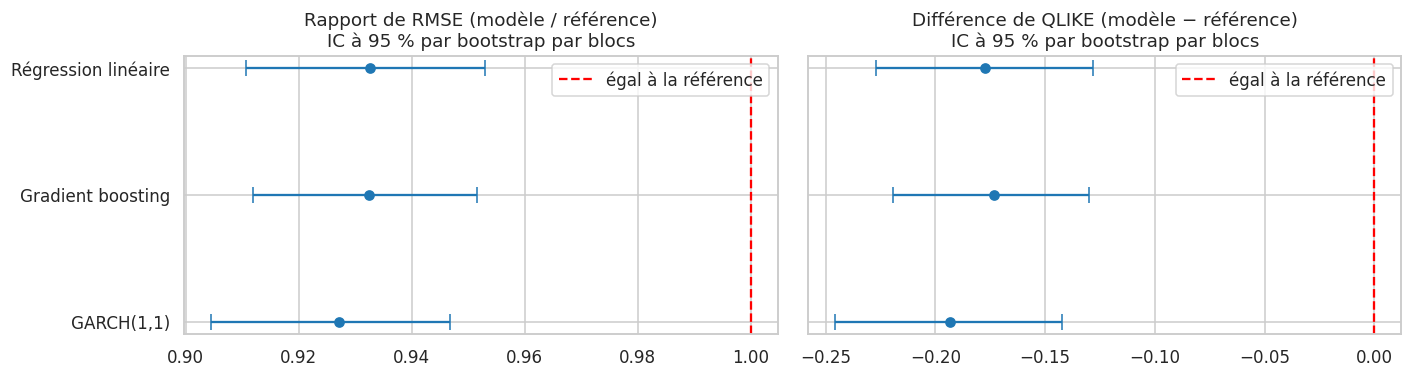

In [ ]:
rng = np.random.default_rng(42)
n = len(test); bloc = 22; B = 2000
e2 = {m: ((test["cible"] - test[m]) ** 2).to_numpy() for m in MODELES}
qk = {m: (np.log(test["h::" + m]) + test["cible_r2"] / test["h::" + m]).to_numpy() for m in MODELES}
nb_blocs = int(np.ceil(n / bloc))
rat, dq = {m: [] for m in MODELES[1:]}, {m: [] for m in MODELES[1:]}
for _ in range(B):
    deb = rng.integers(0, n - bloc + 1, nb_blocs)
    idx = np.concatenate([np.arange(d, d + bloc) for d in deb])[:n]
    ref_r = np.sqrt(e2[MODELES[0]][idx].mean()); ref_q = qk[MODELES[0]][idx].mean()
    for m in MODELES[1:]:
        rat[m].append(np.sqrt(e2[m][idx].mean()) / ref_r); dq[m].append(qk[m][idx].mean() - ref_q)
ic_r = pd.DataFrame({m: np.percentile(v, [2.5, 50, 97.5]) for m, v in rat.items()}, index=["2,5 %", "médiane", "97,5 %"]).T
ic_q = pd.DataFrame({m: np.percentile(v, [2.5, 50, 97.5]) for m, v in dq.items()}, index=["2,5 %", "médiane", "97,5 %"]).T
print("Rapport de RMSE (modèle / référence)"); display(ic_r.round(3))
print("Différence de QLIKE (modèle − référence)"); display(ic_q.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, ic, ligne, titre in [(axes[0], ic_r, 1, "Rapport de RMSE (modèle / référence)"), (axes[1], ic_q, 0, "Différence de QLIKE (modèle − référence)")]:
    y = np.arange(len(ic))
    ax.errorbar(ic["médiane"], y, xerr=[ic["médiane"] - ic["2,5 %"], ic["97,5 %"] - ic["médiane"]], fmt="o", capsize=5, color="tab:blue")
    ax.axvline(ligne, color="red", ls="--", label="égal à la référence")
    ax.set_yticks(y); ax.set_yticklabels(ic.index); ax.invert_yaxis(); ax.set_title(titre + "\nIC à 95 % par bootstrap par blocs"); ax.legend()
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()

In [ ]:
# Contrôle de direction : la prévision d'amplitude ne dit rien du signe du rendement du lendemain
lignes = []
for m in MODELES:
    c, p = stats.pearsonr(test[m], test["cible_r"])
    lignes.append({"Modèle": m, "corr(|r| prévu, r suivant signé)": round(c, 3), "p-value": round(p, 3)})
display(pd.DataFrame(lignes))
ok = int((np.sign(test["r"]) == np.sign(test["cible_r"])).sum())
print(f"Test de direction naïf (le signe d'aujourd'hui annonce celui de demain) : {ok}/{len(test)} = {ok/len(test):.1%}, "
      f"p-value contre 50 % = {stats.binomtest(ok, len(test), 0.5).pvalue:.3f}")

non_signif_dm = (tab_dm.iloc[[i for i, r_ in tab_dm.iterrows() if r_["Comparaison"].endswith("Volatilité historique moyenne")]]["p-value"] > 0.05)
print("\nDM contre la référence :", ", ".join(f"{r_['Comparaison'].split(' contre')[0]} ({r_['Perte']}) p={r_['p-value']}" for _, r_ in tab_dm[tab_dm['Comparaison'].str.endswith('Volatilité historique moyenne')].iterrows()))

,Modèle,"corr(|r| prévu, r suivant signé)",p-value
0,Volatilité historique moyenne,-0.000,0.987
1,Régression linéaire,0.027,0.137
2,Gradient boosting,0.024,0.185
3,"GARCH(1,1)",0.021,0.244


Test de direction naïf (le signe d'aujourd'hui annonce celui de demain) : 1469/2957 = 49.7%, p-value contre 50 % = 0.741

DM contre la référence : Régression linéaire (Erreur quadratique) p=0.0, Régression linéaire (QLIKE) p=0.0, Gradient boosting (Erreur quadratique) p=0.0, Gradient boosting (QLIKE) p=0.0, GARCH(1,1) (Erreur quadratique) p=0.0, GARCH(1,1) (QLIKE) p=0.0


**Lecture.** Contre la référence, toutes les comparaisons sont très significatives (statistiques de −8 à −10 après correction de Newey-West, p-values proches de zéro) et les intervalles de confiance par bootstrap excluent l'égalité : rapport de RMSE entre 0,91 et 0,95, différence de QLIKE entre −0,23 et −0,13. Entre modèles, le boosting n'est pas distinguable de la régression linéaire (p = 0,98 en erreur quadratique, 0,39 en QLIKE). Le GARCH est meilleur que les deux autres avec des p-values d'environ 0,004 à 0,007 ; sur une douzaine de tests, cet avantage est limite (le seuil corrigé de Bonferroni serait d'environ 0,004) et reste très petit en valeur. Côté direction, les prévisions d'amplitude n'ont aucune corrélation avec le signe du rendement suivant (de 0,00 à 0,03, non significatives), et le signe d'aujourd'hui annonce celui de demain 49,7 % du temps (p = 0,74) : **une bonne prévision de volatilité ne donne aucune indication sur le sens du mouvement du change.**

## 12. Synthèse et export

Cette dernière section rassemble les résultats dans un tableau de synthèse, affiche une conclusion rédigée automatiquement à partir des chiffres de cette exécution, puis **exporte** trois fichiers : les prévisions jour par jour (`previsions_eurusd.csv`), les métriques (`metriques_eurusd.csv`) et la table d'apprentissage SQL (`variables_eurusd.csv`). Sur Colab, les fichiers sont téléchargés sur votre ordinateur ; ailleurs, ils sont écrits dans le dossier courant.

In [ ]:
synth = resultats.copy()
synth["Type"] = ["référence", "linéaire", "arbres", "GARCH"]
synth = synth[["Modèle", "Type", "RMSE (%)", "QLIKE", "RMSE / référence", "QLIKE − référence"]]
display(synth.round(4))

mq = synth.loc[synth["QLIKE"].idxmin()]; mr = synth.loc[synth["RMSE (%)"].idxmin()]
print("SYNTHÈSE")
print(f"- Référence (volatilité historique moyenne) : RMSE {synth.loc[0,'RMSE (%)']:.4f} %, QLIKE {synth.loc[0,'QLIKE']:.4f}.")
print(f"- Meilleur en RMSE : {mr['Modèle']} (rapport {mr['RMSE / référence']:.3f}). Meilleur en QLIKE : {mq['Modèle']} (écart {mq['QLIKE − référence']:+.4f}).")
contre_ref = tab_dm[tab_dm["Comparaison"].str.endswith("Volatilité historique moyenne")]
if (contre_ref["p-value"] < 0.05).any():
    print("- Au moins un modèle bat significativement la référence à 5 % (Diebold-Mariano, voir le tableau) : le passé aide à prévoir l'amplitude.")
else:
    print("- Aucun écart avec la référence n'est significatif à 5 % : le passé n'aide pas de façon démontrée.")
print(f"- Même la prévision parfaite de la volatilité (oracle) laisse un RMSE de {rmse_or:.3f} % sur |r| : une erreur « élevée » n'est pas forcément une mauvaise prévision.")
print(f"- Erreur par régime : de {rm.min().min():.2f} % à {rm.max().max():.2f} % de RMSE selon la période, dominée par les épisodes de stress.")

,Modèle,Type,RMSE (%),QLIKE,RMSE / référence,QLIKE − référence
0,Volatilité historique moyenne,référence,0.3400,-0.3669,1.0000,0.0000
1,Régression linéaire,linéaire,0.3173,-0.5429,0.9335,-0.1761
2,Gradient boosting,arbres,0.3173,-0.5392,0.9335,-0.1723
3,"GARCH(1,1)",GARCH,0.3154,-0.5592,0.9279,-0.1923


SYNTHÈSE
- Référence (volatilité historique moyenne) : RMSE 0.3400 %, QLIKE -0.3669.
- Meilleur en RMSE : GARCH(1,1) (rapport 0.928). Meilleur en QLIKE : GARCH(1,1) (écart -0.1923).
- Au moins un modèle bat significativement la référence à 5 % (Diebold-Mariano, voir le tableau) : le passé aide à prévoir l'amplitude.
- Même la prévision parfaite de la volatilité (oracle) laisse un RMSE de 0.316 % sur |r| : une erreur « élevée » n'est pas forcément une mauvaise prévision.
- Erreur par régime : de 0.24 % à 0.44 % de RMSE selon la période, dominée par les épisodes de stress.


In [ ]:
# Export
test_export = test[["date_cible", "cible", "cible_r2", "regime"] + MODELES]
test_export.to_csv("previsions_eurusd.csv", index=False)
synth.to_csv("metriques_eurusd.csv", index=False)
dat.drop(columns=["date"]).to_csv("variables_eurusd.csv", index=False)
print("Fichiers écrits : previsions_eurusd.csv, metriques_eurusd.csv, variables_eurusd.csv")
try:
    from google.colab import files
    for f in ["previsions_eurusd.csv", "metriques_eurusd.csv", "variables_eurusd.csv"]:
        files.download(f)
except Exception:
    pass

Fichiers écrits : previsions_eurusd.csv, metriques_eurusd.csv, variables_eurusd.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Ce qu'il faut retenir.**

1. **Réponse à la question.** Oui, le passé du taux de change aide à prévoir l'**amplitude** des variations à venir, et le résultat est robuste : la régression linéaire, le gradient boosting et le GARCH réduisent le RMSE d'environ 7 % et améliorent nettement la QLIKE par rapport à la volatilité historique moyenne, dans toutes les périodes et sans les épisodes extrêmes. En revanche, le passé ne dit rien du **sens** des variations.
2. **Pourquoi ça marche.** La volatilité est persistante : l'autocorrélation de |r| reste positive pendant des semaines. Les moyennes sur 22 et 66 jours portent l'essentiel de l'information, d'où l'absence de gain du boosting sur la régression linéaire.
3. **Pourquoi le gain paraît faible en RMSE.** |r| est un proxy très bruité : même un oracle qui connaît la volatilité voisine ne ferait pas beaucoup mieux (section 6). Une erreur faible ne doit pas être lue comme une bonne prévision de direction, et une erreur élevée n'est pas une preuve de mauvais modèle ; la QLIKE est plus informative ici.
4. **Préparation en SQL.** Jours sans cotation retirés avant tout calcul, rendements logarithmiques par `LAG`, retards et moyennes mobiles par fonctions de fenêtre, cible par `LEAD`, référence par moyenne cumulée, régimes joints après coup pour le diagnostic uniquement.
5. **Limites.** Les modèles réagissent aux chocs après coup (Covid, 2022) : ils ne les anticipent pas. La référence (moyenne depuis 1999) est volontairement simple ; une moyenne mobile sur 22 jours serait un adversaire plus dur. Le GARCH a un avantage faible et peu robuste à la multiplicité des tests. La source est un relevé quotidien unique, pas des données intrajournalières.

**Pour aller plus loin.** Comparer avec une moyenne mobile simple sur 22 jours comme référence ; essayer un GARCH asymétrique (GJR, EGARCH) ou une régression de type HAR ; ajouter des variables explicatives externes (écart de taux BCE / Fed, indice de volatilité VIX) ; prévoir à 5 ou 22 jours, où le bruit du proxy pèse moins ; utiliser une volatilité réalisée calculée à partir de données intrajournalières, bien moins bruitée que |r|.